In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("All libraries loaded successfully!")

OpenCV version: 4.13.0
NumPy version: 2.4.6
All libraries loaded successfully!


In [2]:
# Images folder ka path define karta hai
IMAGE_DIR = r'C:\Projects\Internship_Learning\dataset\images'
# Images folder ki sabhi image files ki list leta hai
# Sirf valid image extensions wali files leta hai (folders/checkpoints ignore ho jate hain)
images = [f for f in os.listdir(IMAGE_DIR) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
# Total images ki count print karta hai
print("Images found:", len(images))
# Har image ka naam ek-ek karke print karta hai
for img in images:
    print(" -", img)

Images found: 50
 - Screenshot 2026-06-23 132015.png
 - Screenshot 2026-06-23 132334.png
 - Screenshot 2026-06-23 132939.png
 - Screenshot 2026-06-23 133431.png
 - Screenshot 2026-06-23 140930.png
 - Screenshot 2026-06-23 140957.png
 - Screenshot 2026-06-23 141031.png
 - Screenshot 2026-06-23 141056.png
 - Screenshot 2026-06-23 141120.png
 - Screenshot 2026-06-23 141744.png
 - Screenshot 2026-06-23 141920.png
 - Screenshot 2026-06-23 141947.png
 - Screenshot 2026-06-23 142025.png
 - Screenshot 2026-06-23 142056.png
 - Screenshot 2026-06-23 142134.png
 - Screenshot 2026-06-23 142153.png
 - Screenshot 2026-06-23 142813.png
 - Screenshot 2026-06-23 143059.png
 - Screenshot 2026-06-23 143140.png
 - Screenshot 2026-06-23 143213.png
 - Screenshot 2026-06-23 143230.png
 - Screenshot 2026-06-23 143250.png
 - Screenshot 2026-06-23 143314.png
 - Screenshot 2026-06-23 143340.png
 - Screenshot 2026-06-23 143513.png
 - Screenshot 2026-06-23 143546.png
 - Screenshot 2026-06-23 143612.png
 - Screensh

Image name: Screenshot 2026-06-23 132015.png
Shape (Height, Width, Channels): (973, 1899, 3)
Height: 973 px
Width: 1899 px
Channels: 3


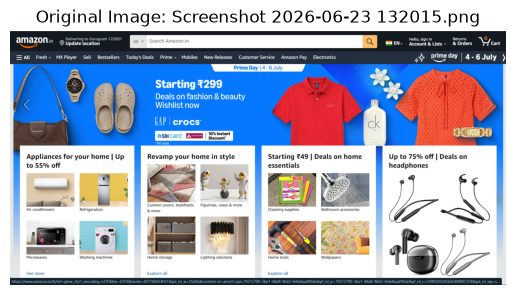

In [3]:
# Pehli image ka complete path banata hai
img_path = os.path.join(IMAGE_DIR, images[0])

# OpenCV ki help se image read karta hai
img = cv2.imread(img_path)

# Image ko BGR format se RGB format me convert karta hai
# (Matplotlib RGB format use karta hai)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Image ka naam print karta hai
print("Image name:", images[0])

# Image ki shape (Height, Width, Channels) print karta hai
print("Shape (Height, Width, Channels):", img.shape)

# Image ki height print karta hai
print("Height:", img.shape[0], "px")

# Image ki width print karta hai
print("Width:", img.shape[1], "px")

# Image me total color channels print karta hai
print("Channels:", img.shape[2])

# Image display karta hai
plt.imshow(img_rgb)

# Image ka title set karta hai
plt.title("Original Image: " + images[0])

# Axis hide karta hai
plt.axis('off')

# Image screen par show karta hai
plt.show()

Original size: (973, 1899, 3)
Resized size: (224, 224, 3)


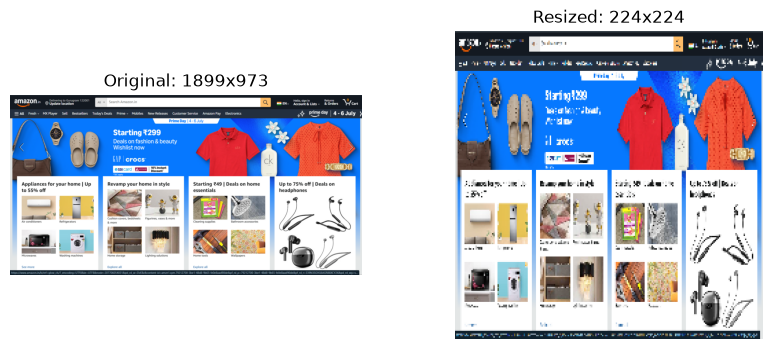

In [4]:
# Image ko 224x224 size me resize karta hai
img_resized = cv2.resize(img_rgb, (224, 224))
# Original image ka size print karta hai
print("Original size:", img_rgb.shape)
# Resized image ka size print karta hai
print("Resized size:", img_resized.shape)

# Figure ka size set karta hai
plt.figure(figsize=(10, 4))

# Pehla subplot create karta hai
plt.subplot(1, 2, 1)
# Original image display karta hai
plt.imshow(img_rgb)
# Original image ka title set karta hai (actual shape se dynamically banaya)
plt.title(f"Original: {img_rgb.shape[1]}x{img_rgb.shape[0]}")
# Axis hide karta hai
plt.axis('off')

# Dusra subplot create karta hai
plt.subplot(1, 2, 2)
# Resized image display karta hai
plt.imshow(img_resized)
# Resized image ka title set karta hai
plt.title("Resized: 224x224")
# Axis hide karta hai
plt.axis('off')

# Dono images display karta hai
plt.show()

Grayscale image shape: (224, 224)


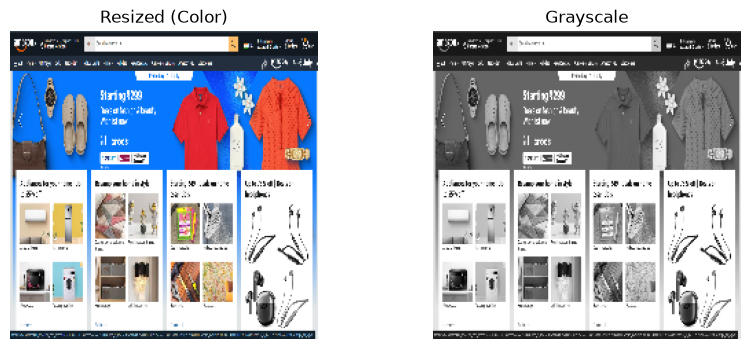

In [5]:
# Resized image ko grayscale me convert karta hai
img_gray = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)

# Grayscale image ka shape print karta hai
print("Grayscale image shape:", img_gray.shape)

# Figure ka size set karta hai
plt.figure(figsize=(10, 4))

# Pehla subplot create karta hai
plt.subplot(1, 2, 1)

# Original color image display karta hai
plt.imshow(img_resized)

# Original image ka title set karta hai
plt.title("Resized (Color)")

# Axis hide karta hai
plt.axis('off')

# Dusra subplot create karta hai
plt.subplot(1, 2, 2)

# Grayscale image display karta hai
plt.imshow(img_gray, cmap='gray')

# Grayscale image ka title set karta hai
plt.title("Grayscale")

# Axis hide karta hai
plt.axis('off')

# Dono images display karta hai
plt.show()

In [6]:
# Calculate average brightness
# np.mean() image ke sabhi pixel values ka average nikalta hai
# Iska use image ki overall brightness calculate karne ke liye kiya jata hai
brightness = np.mean(img_gray)

# Brightness value print karta hai (0 se 255 ke beech)
print("Average Brightness:", round(brightness, 2), "/ 255")

# Brightness ke basis par image ka theme identify karta hai
if brightness > 180:
    print("Theme: Light/White background")

# Agar brightness kam ho to dark theme print karta hai
elif brightness < 80:
    print("Theme: Dark background")

# Baaki cases me mid-range theme print karta hai
else:
    print("Theme: Mid-range")

Average Brightness: 159.84 / 255
Theme: Mid-range


In [7]:
# Calculate contrast (standard deviation of pixel values)
# np.std() pixel values ka standard deviation calculate karta hai
# Iska use image ka overall contrast measure karne ke liye kiya jata hai
contrast = np.std(img_gray)

# Contrast value print karta hai
print("Contrast (Std Dev):", round(contrast, 2))

# Contrast ke basis par image quality interpret karta hai
if contrast > 70:
    print("Contrast: High — strong visual separation between elements")

# Medium contrast hone par message print karta hai
elif contrast > 30:
    print("Contrast: Medium — moderate visual variation")

# Low contrast hone par message print karta hai
else:
    print("Contrast: Low — elements hard to distinguish")

Contrast (Std Dev): 82.34
Contrast: High — strong visual separation between elements


Edge Density: 20.8 %
Layout: Complex — many elements, borders, icons


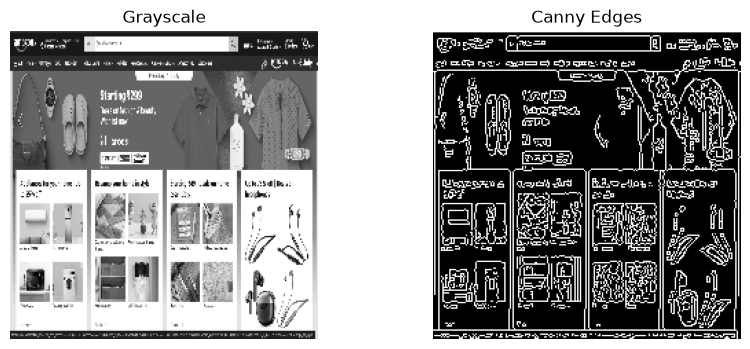

In [8]:
# Canny Edge Detection apply karta hai
# Iska use image ke important edges detect karne ke liye kiya jata hai
edges = cv2.Canny(img_gray, 50, 150)

# Edge pixels ka percentage (edge density) calculate karta hai
edge_density = np.sum(edges > 0) / edges.size * 100

# Edge density print karta hai
print("Edge Density:", round(edge_density, 2), "%")

# Edge density ke basis par layout complexity identify karta hai
if edge_density > 15:
    print("Layout: Complex — many elements, borders, icons")

# Medium edge density hone par balanced layout print karta hai
elif edge_density > 5:
    print("Layout: Moderate — balanced elements")

# Low edge density hone par simple layout print karta hai
else:
    print("Layout: Simple — clean, minimal design")

# Figure ka size set karta hai
plt.figure(figsize=(10, 4))

# Pehla subplot create karta hai
plt.subplot(1, 2, 1)

# Grayscale image display karta hai
plt.imshow(img_gray, cmap='gray')

# Title set karta hai
plt.title("Grayscale")

# Axis hide karta hai
plt.axis('off')

# Dusra subplot create karta hai
plt.subplot(1, 2, 2)

# Edge-detected image display karta hai
plt.imshow(edges, cmap='gray')

# Title set karta hai
plt.title("Canny Edges")

# Axis hide karta hai
plt.axis('off')

# Dono images display karta hai
plt.show()

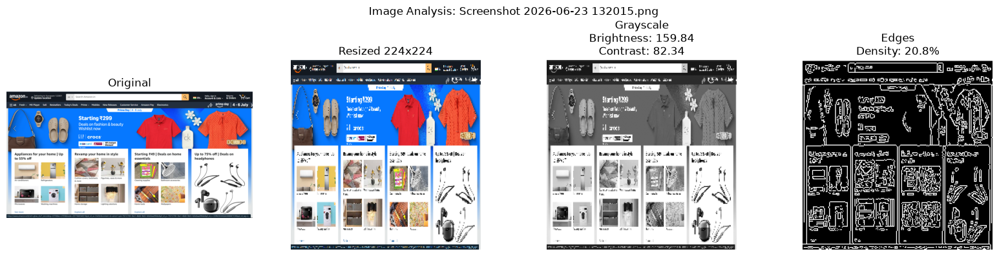

In [9]:
# Display all 4 views together for one image
# Figure ka size set karta hai
plt.figure(figsize=(16, 4))

# Pehla subplot create karta hai
plt.subplot(1, 4, 1)

# Original image display karta hai
plt.imshow(img_rgb)

# Title set karta hai
plt.title("Original")

# Axis hide karta hai
plt.axis('off')

# Dusra subplot create karta hai
plt.subplot(1, 4, 2)

# Resized image display karta hai
plt.imshow(img_resized)

# Title set karta hai
plt.title("Resized 224x224")

# Axis hide karta hai
plt.axis('off')

# Teesra subplot create karta hai
plt.subplot(1, 4, 3)

# Grayscale image display karta hai
plt.imshow(img_gray, cmap='gray')

# Grayscale image ke saath brightness aur contrast bhi show karta hai
plt.title(f"Grayscale\nBrightness: {round(brightness, 2)}\nContrast: {round(contrast, 2)}")

# Axis hide karta hai
plt.axis('off')

# Chautha subplot create karta hai
plt.subplot(1, 4, 4)

# Edge-detected image display karta hai
plt.imshow(edges, cmap='gray')

# Edge density ke saath title set karta hai
plt.title(f"Edges\nDensity: {round(edge_density, 2)}%")

# Axis hide karta hai
plt.axis('off')

# Puri figure ka main title set karta hai
plt.suptitle("Image Analysis: " + images[0], fontsize=12)

# Layout automatically adjust karta hai taaki plots overlap na hon
plt.tight_layout()

# Sabhi images ek saath display karta hai
plt.show()

PROCESSING ALL 50 IMAGES


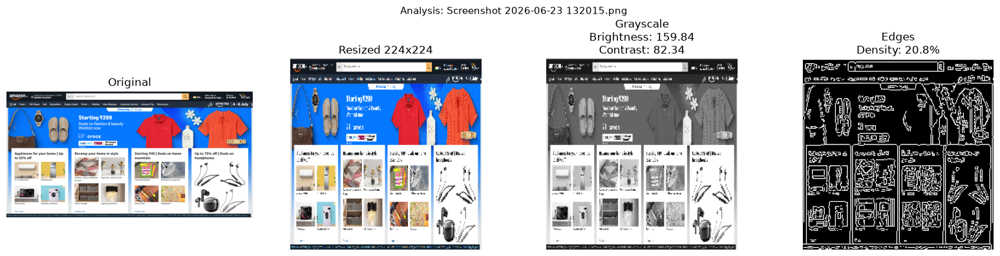

Image: Screenshot 2026-06-23 132015.png
  Brightness : 159.84/255
  Contrast   : 82.34
  Edge Density: 20.8%
----------------------------------------


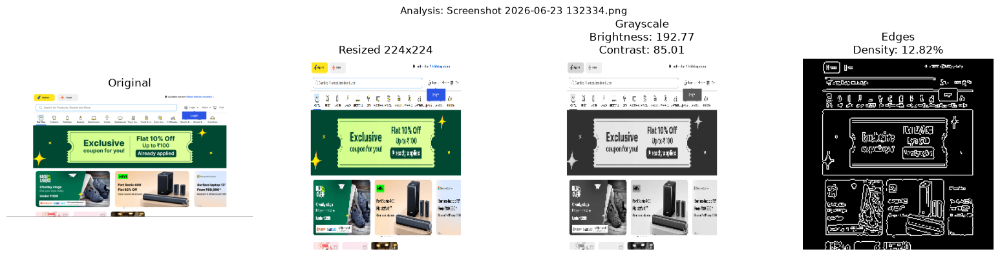

Image: Screenshot 2026-06-23 132334.png
  Brightness : 192.77/255
  Contrast   : 85.01
  Edge Density: 12.82%
----------------------------------------


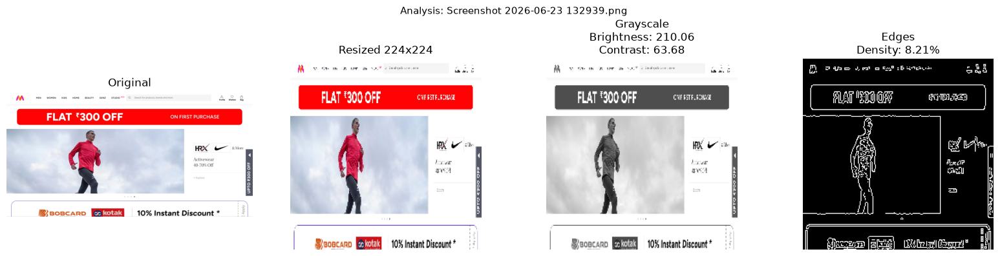

Image: Screenshot 2026-06-23 132939.png
  Brightness : 210.06/255
  Contrast   : 63.68
  Edge Density: 8.21%
----------------------------------------


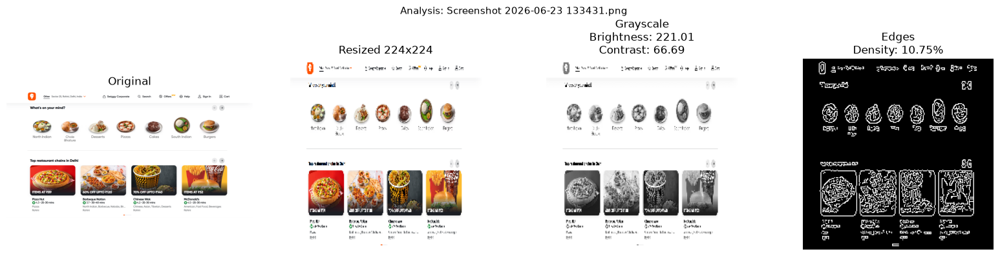

Image: Screenshot 2026-06-23 133431.png
  Brightness : 221.01/255
  Contrast   : 66.69
  Edge Density: 10.75%
----------------------------------------


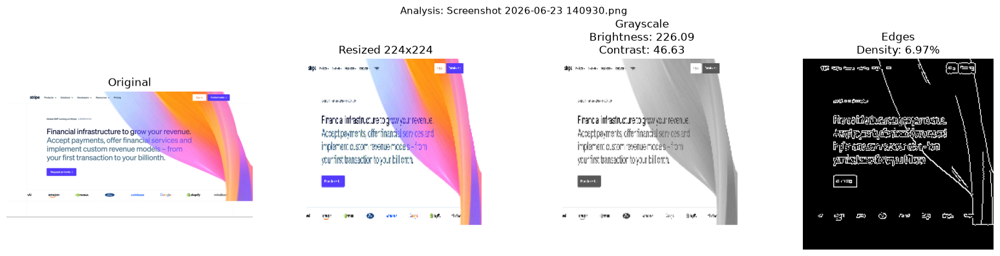

Image: Screenshot 2026-06-23 140930.png
  Brightness : 226.09/255
  Contrast   : 46.63
  Edge Density: 6.97%
----------------------------------------


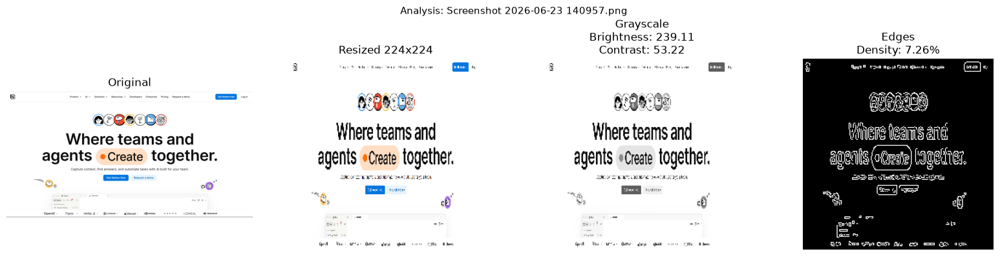

Image: Screenshot 2026-06-23 140957.png
  Brightness : 239.11/255
  Contrast   : 53.22
  Edge Density: 7.26%
----------------------------------------


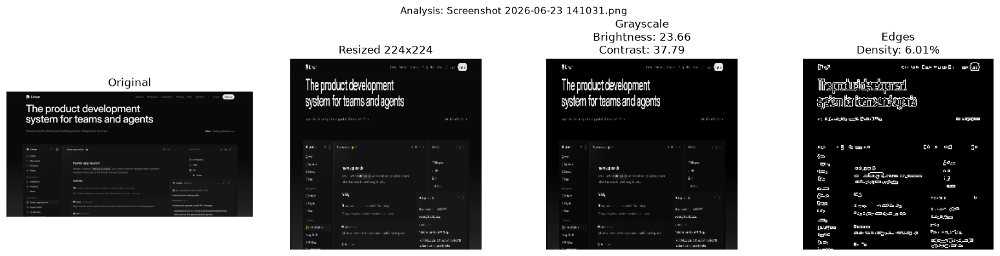

Image: Screenshot 2026-06-23 141031.png
  Brightness : 23.66/255
  Contrast   : 37.79
  Edge Density: 6.01%
----------------------------------------


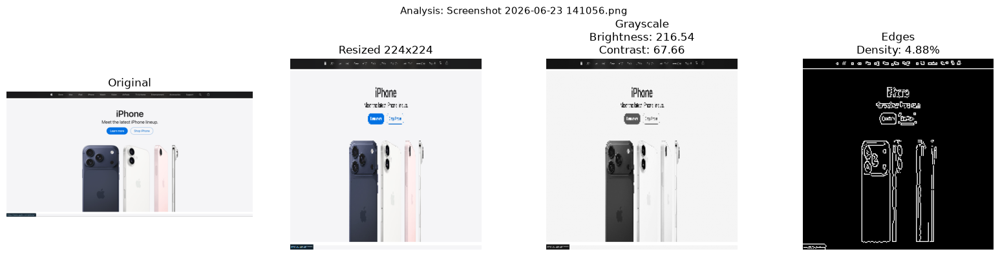

Image: Screenshot 2026-06-23 141056.png
  Brightness : 216.54/255
  Contrast   : 67.66
  Edge Density: 4.88%
----------------------------------------


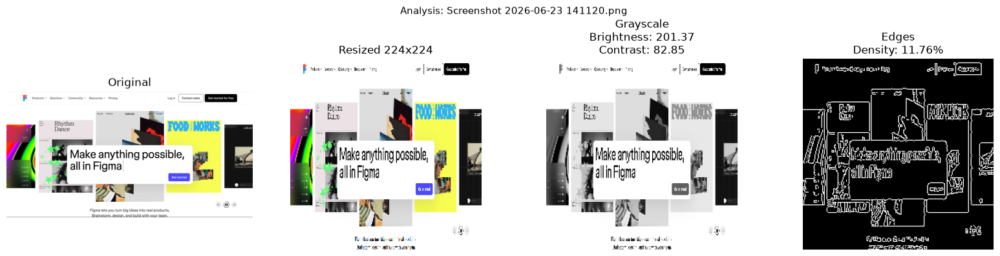

Image: Screenshot 2026-06-23 141120.png
  Brightness : 201.37/255
  Contrast   : 82.85
  Edge Density: 11.76%
----------------------------------------


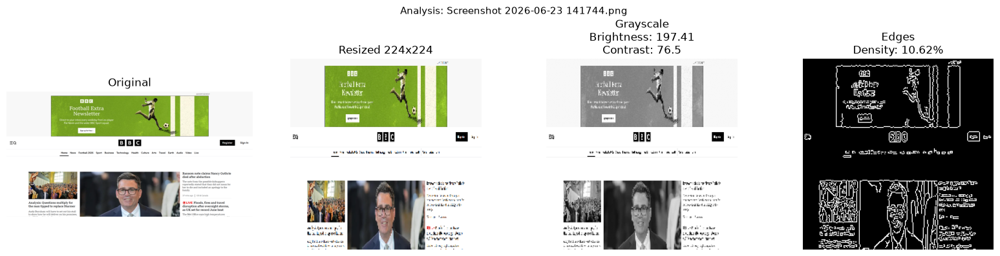

Image: Screenshot 2026-06-23 141744.png
  Brightness : 197.41/255
  Contrast   : 76.5
  Edge Density: 10.62%
----------------------------------------


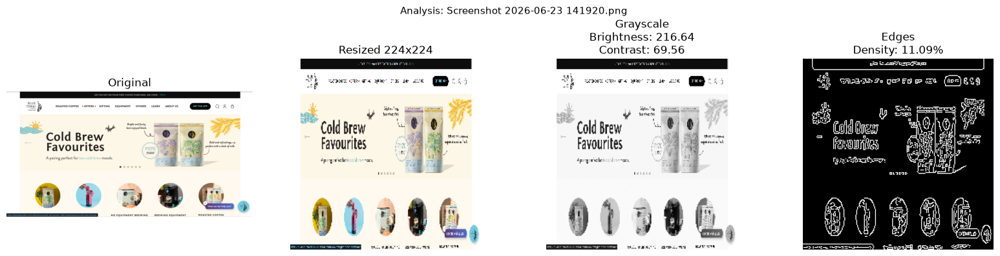

Image: Screenshot 2026-06-23 141920.png
  Brightness : 216.64/255
  Contrast   : 69.56
  Edge Density: 11.09%
----------------------------------------


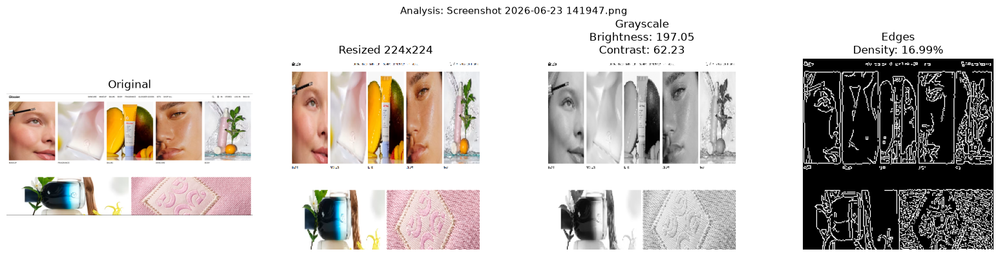

Image: Screenshot 2026-06-23 141947.png
  Brightness : 197.05/255
  Contrast   : 62.23
  Edge Density: 16.99%
----------------------------------------


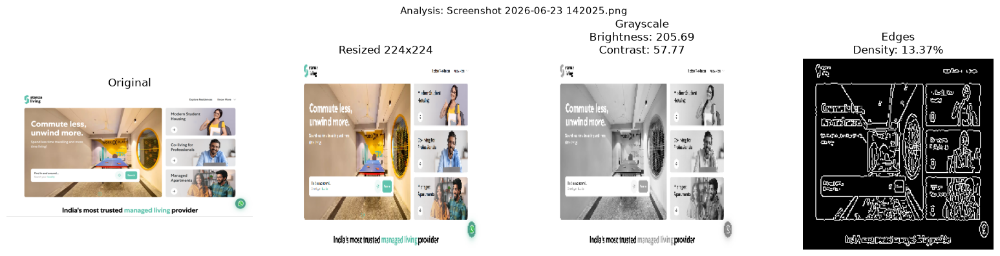

Image: Screenshot 2026-06-23 142025.png
  Brightness : 205.69/255
  Contrast   : 57.77
  Edge Density: 13.37%
----------------------------------------


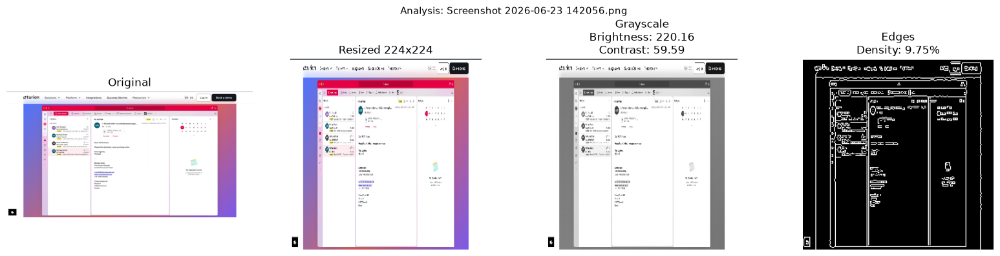

Image: Screenshot 2026-06-23 142056.png
  Brightness : 220.16/255
  Contrast   : 59.59
  Edge Density: 9.75%
----------------------------------------


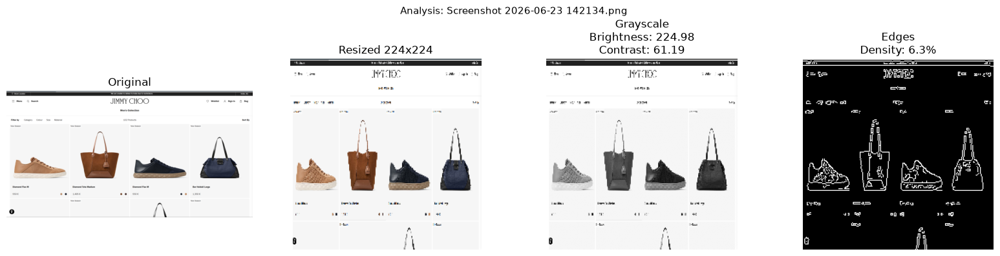

Image: Screenshot 2026-06-23 142134.png
  Brightness : 224.98/255
  Contrast   : 61.19
  Edge Density: 6.3%
----------------------------------------


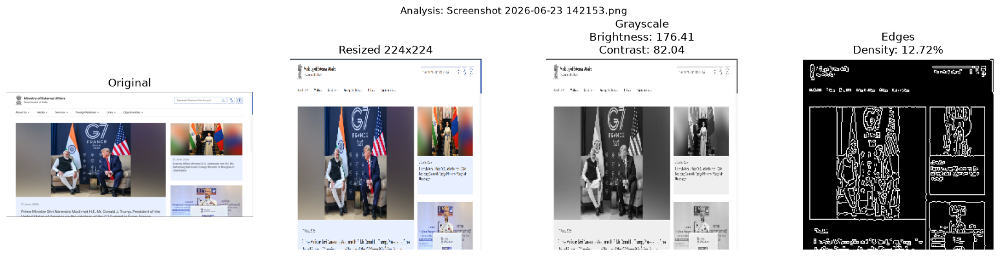

Image: Screenshot 2026-06-23 142153.png
  Brightness : 176.41/255
  Contrast   : 82.04
  Edge Density: 12.72%
----------------------------------------


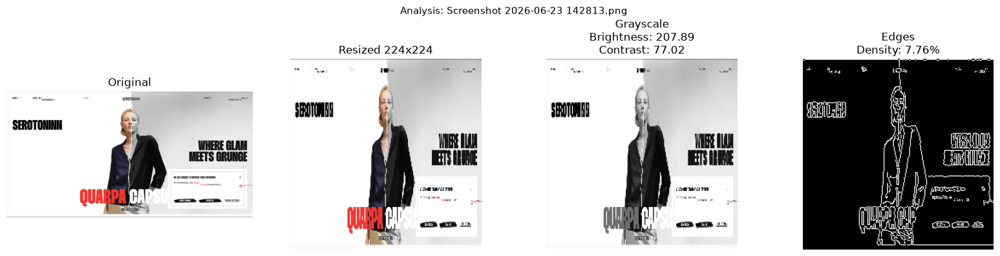

Image: Screenshot 2026-06-23 142813.png
  Brightness : 207.89/255
  Contrast   : 77.02
  Edge Density: 7.76%
----------------------------------------


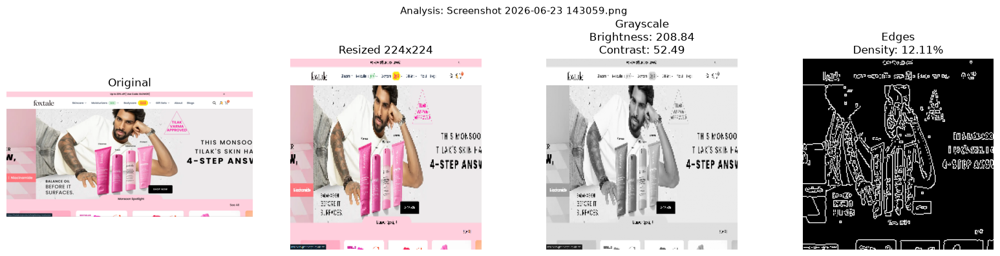

Image: Screenshot 2026-06-23 143059.png
  Brightness : 208.84/255
  Contrast   : 52.49
  Edge Density: 12.11%
----------------------------------------


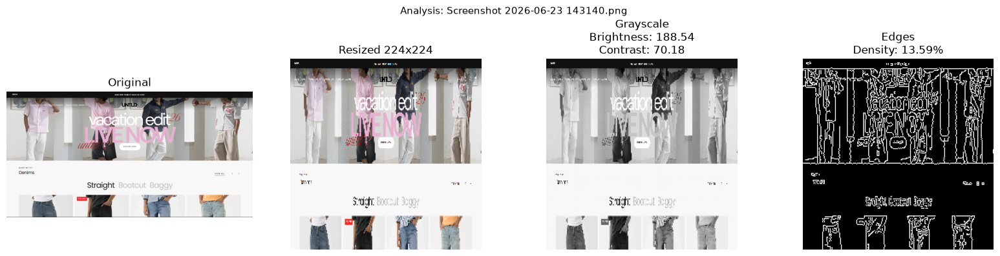

Image: Screenshot 2026-06-23 143140.png
  Brightness : 188.54/255
  Contrast   : 70.18
  Edge Density: 13.59%
----------------------------------------


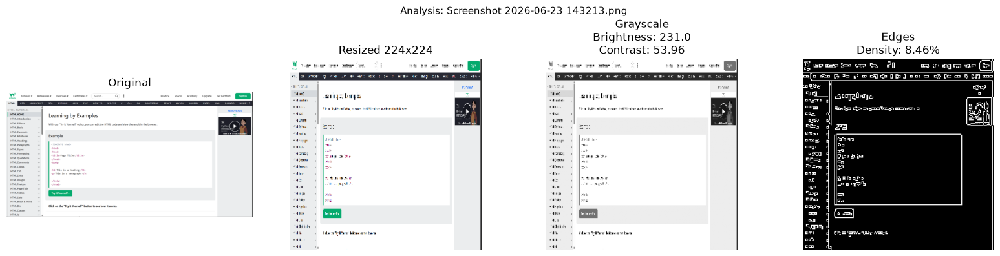

Image: Screenshot 2026-06-23 143213.png
  Brightness : 231.0/255
  Contrast   : 53.96
  Edge Density: 8.46%
----------------------------------------


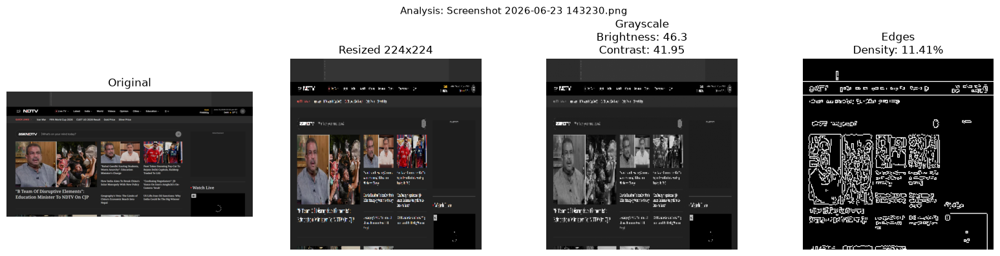

Image: Screenshot 2026-06-23 143230.png
  Brightness : 46.3/255
  Contrast   : 41.95
  Edge Density: 11.41%
----------------------------------------


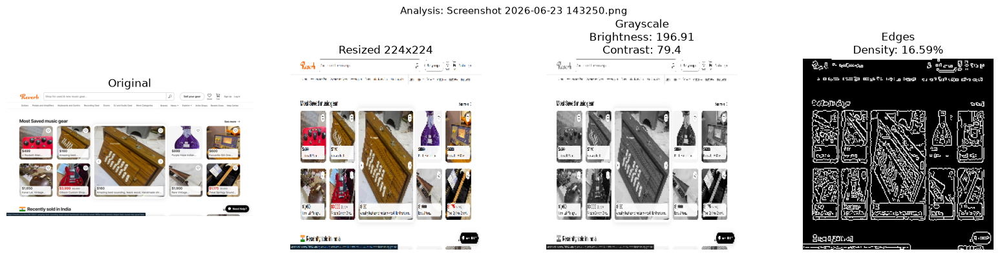

Image: Screenshot 2026-06-23 143250.png
  Brightness : 196.91/255
  Contrast   : 79.4
  Edge Density: 16.59%
----------------------------------------


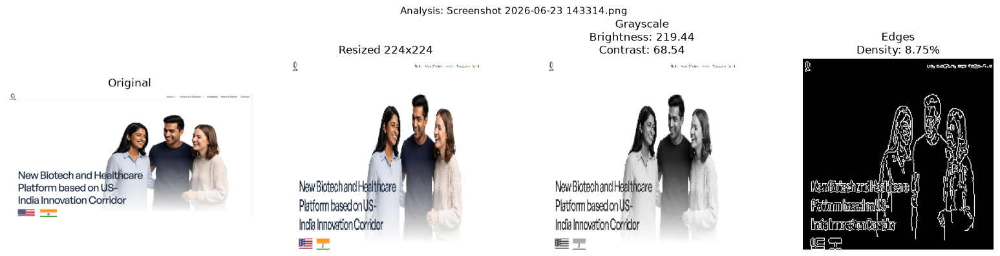

Image: Screenshot 2026-06-23 143314.png
  Brightness : 219.44/255
  Contrast   : 68.54
  Edge Density: 8.75%
----------------------------------------


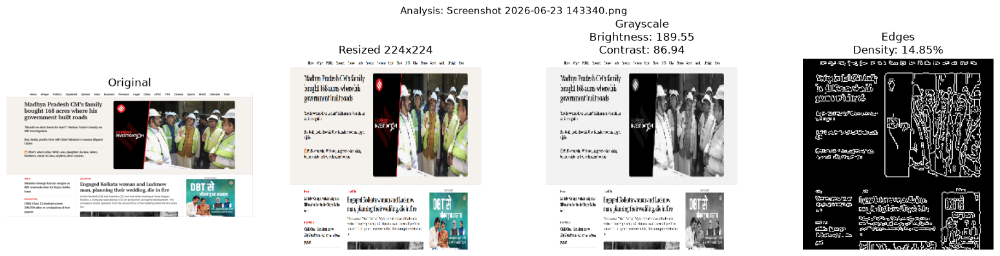

Image: Screenshot 2026-06-23 143340.png
  Brightness : 189.55/255
  Contrast   : 86.94
  Edge Density: 14.85%
----------------------------------------


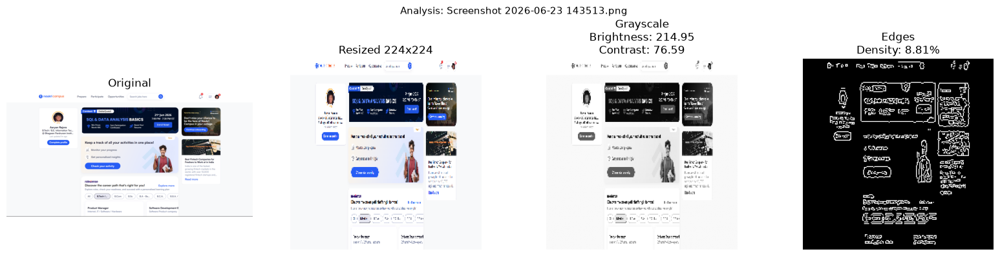

Image: Screenshot 2026-06-23 143513.png
  Brightness : 214.95/255
  Contrast   : 76.59
  Edge Density: 8.81%
----------------------------------------


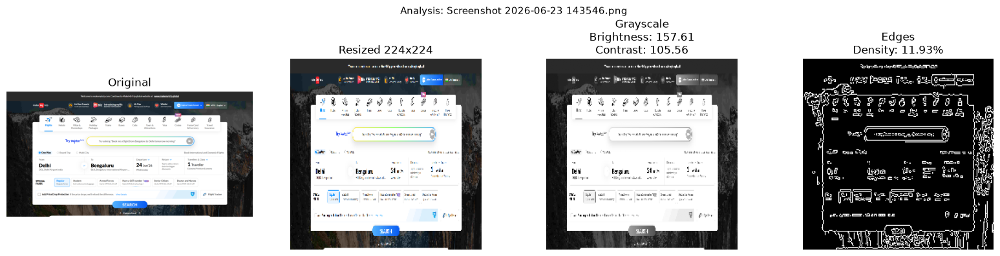

Image: Screenshot 2026-06-23 143546.png
  Brightness : 157.61/255
  Contrast   : 105.56
  Edge Density: 11.93%
----------------------------------------


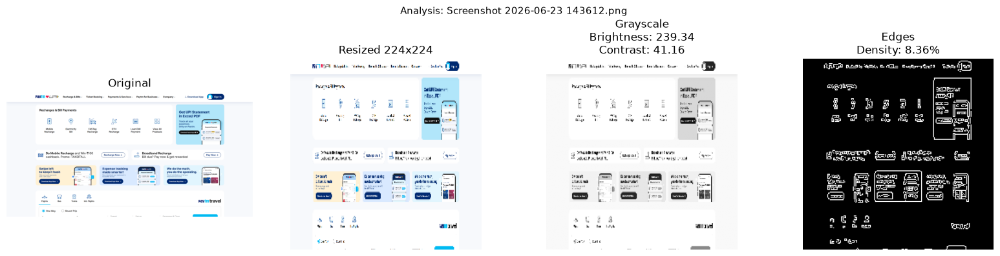

Image: Screenshot 2026-06-23 143612.png
  Brightness : 239.34/255
  Contrast   : 41.16
  Edge Density: 8.36%
----------------------------------------


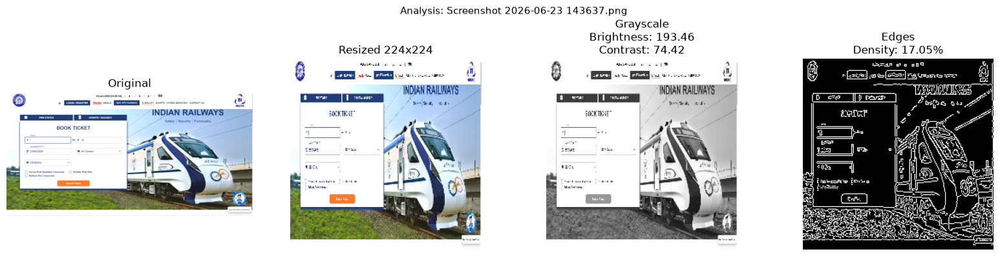

Image: Screenshot 2026-06-23 143637.png
  Brightness : 193.46/255
  Contrast   : 74.42
  Edge Density: 17.05%
----------------------------------------


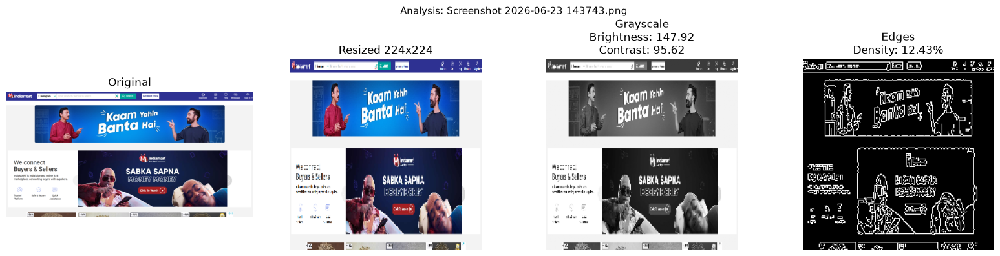

Image: Screenshot 2026-06-23 143743.png
  Brightness : 147.92/255
  Contrast   : 95.62
  Edge Density: 12.43%
----------------------------------------


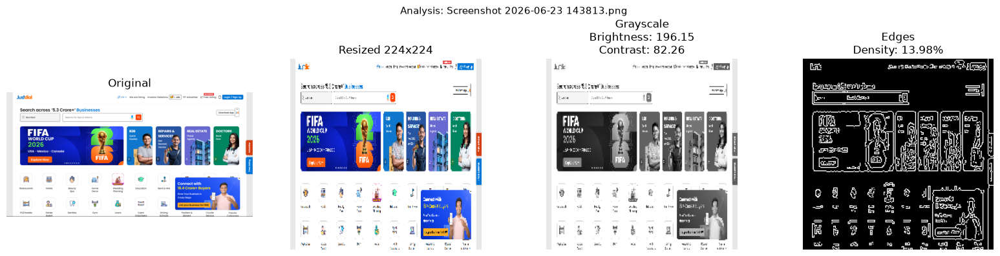

Image: Screenshot 2026-06-23 143813.png
  Brightness : 196.15/255
  Contrast   : 82.26
  Edge Density: 13.98%
----------------------------------------


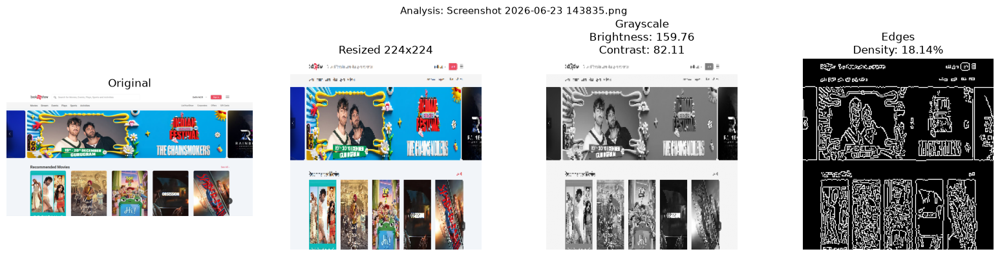

Image: Screenshot 2026-06-23 143835.png
  Brightness : 159.76/255
  Contrast   : 82.11
  Edge Density: 18.14%
----------------------------------------


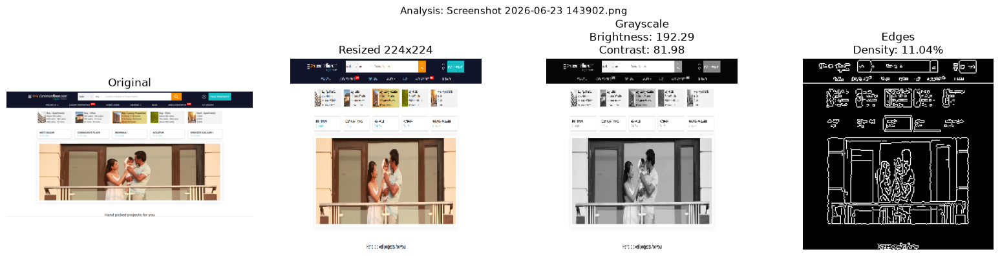

Image: Screenshot 2026-06-23 143902.png
  Brightness : 192.29/255
  Contrast   : 81.98
  Edge Density: 11.04%
----------------------------------------


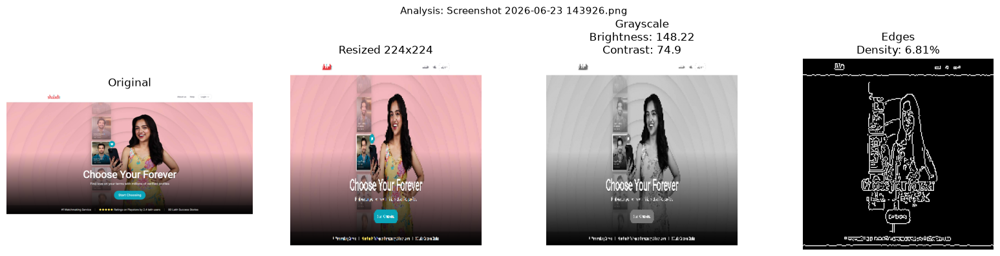

Image: Screenshot 2026-06-23 143926.png
  Brightness : 148.22/255
  Contrast   : 74.9
  Edge Density: 6.81%
----------------------------------------


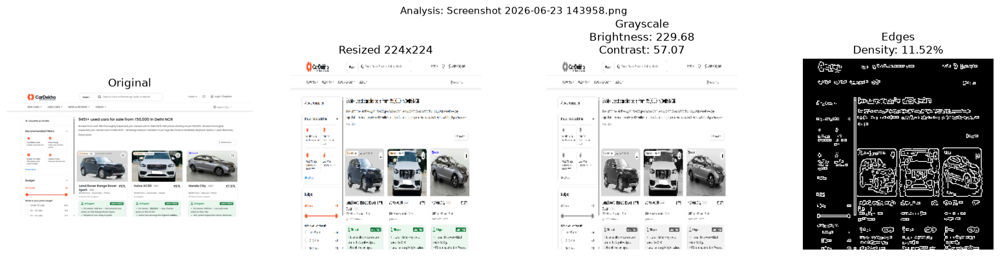

Image: Screenshot 2026-06-23 143958.png
  Brightness : 229.68/255
  Contrast   : 57.07
  Edge Density: 11.52%
----------------------------------------


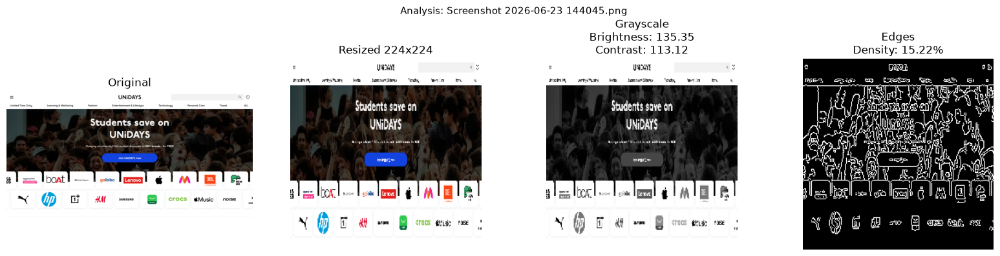

Image: Screenshot 2026-06-23 144045.png
  Brightness : 135.35/255
  Contrast   : 113.12
  Edge Density: 15.22%
----------------------------------------


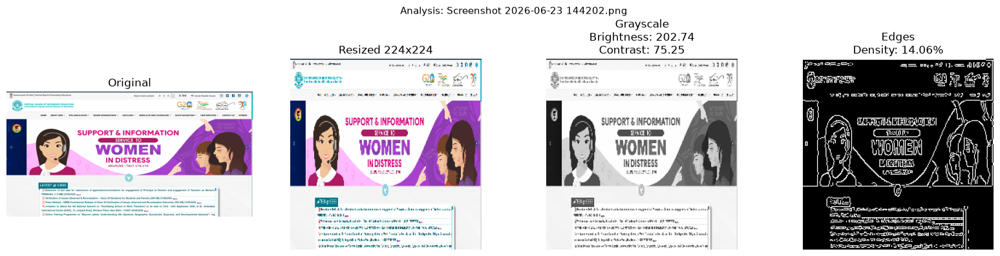

Image: Screenshot 2026-06-23 144202.png
  Brightness : 202.74/255
  Contrast   : 75.25
  Edge Density: 14.06%
----------------------------------------


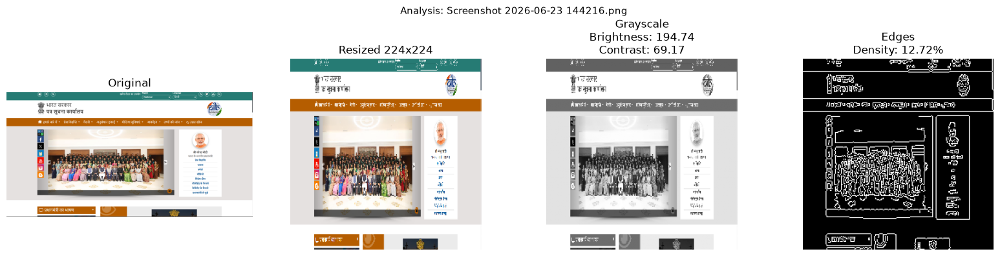

Image: Screenshot 2026-06-23 144216.png
  Brightness : 194.74/255
  Contrast   : 69.17
  Edge Density: 12.72%
----------------------------------------


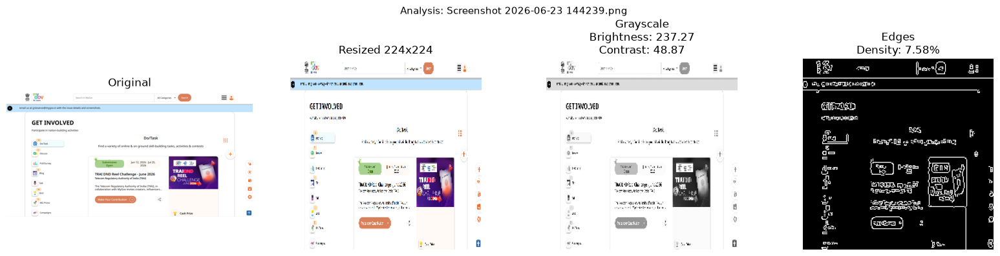

Image: Screenshot 2026-06-23 144239.png
  Brightness : 237.27/255
  Contrast   : 48.87
  Edge Density: 7.58%
----------------------------------------


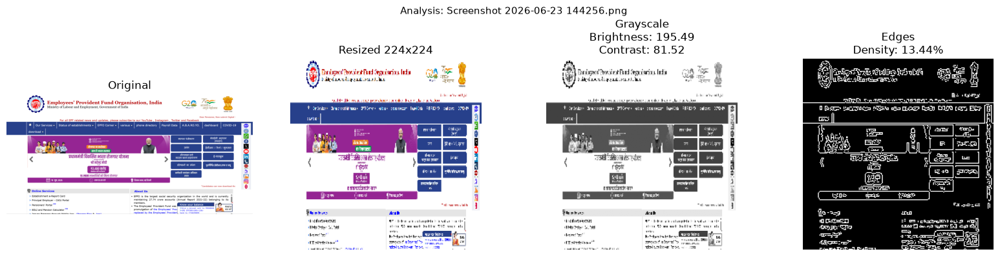

Image: Screenshot 2026-06-23 144256.png
  Brightness : 195.49/255
  Contrast   : 81.52
  Edge Density: 13.44%
----------------------------------------


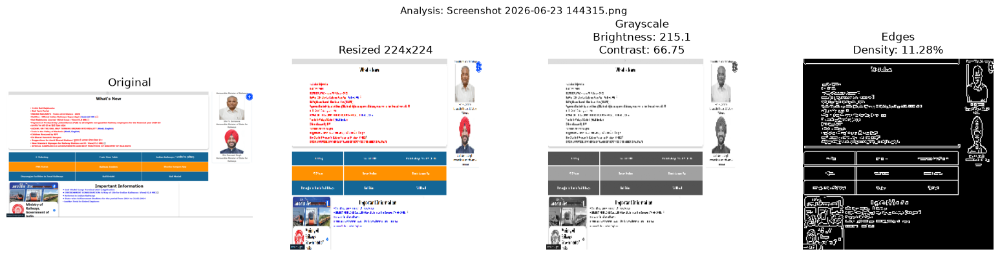

Image: Screenshot 2026-06-23 144315.png
  Brightness : 215.1/255
  Contrast   : 66.75
  Edge Density: 11.28%
----------------------------------------


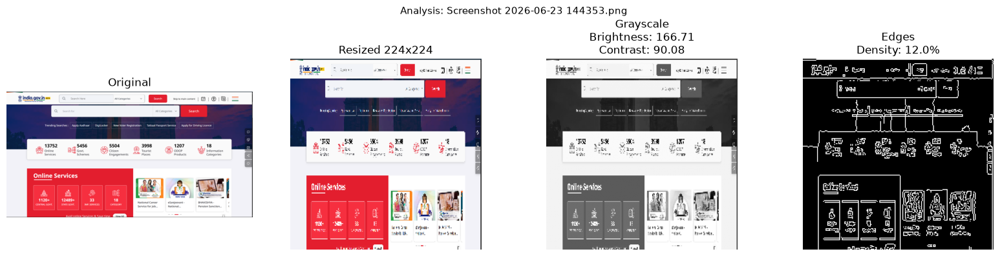

Image: Screenshot 2026-06-23 144353.png
  Brightness : 166.71/255
  Contrast   : 90.08
  Edge Density: 12.0%
----------------------------------------


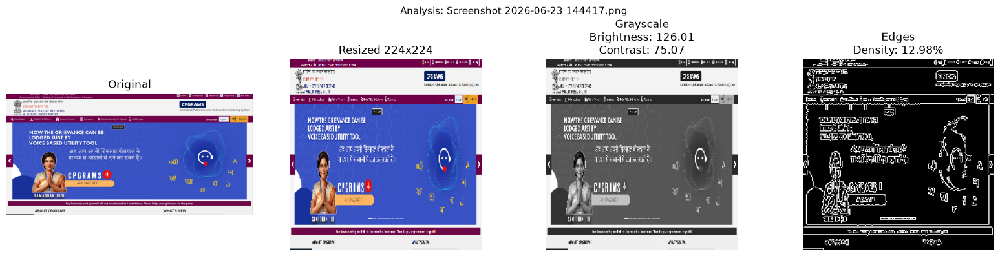

Image: Screenshot 2026-06-23 144417.png
  Brightness : 126.01/255
  Contrast   : 75.07
  Edge Density: 12.98%
----------------------------------------


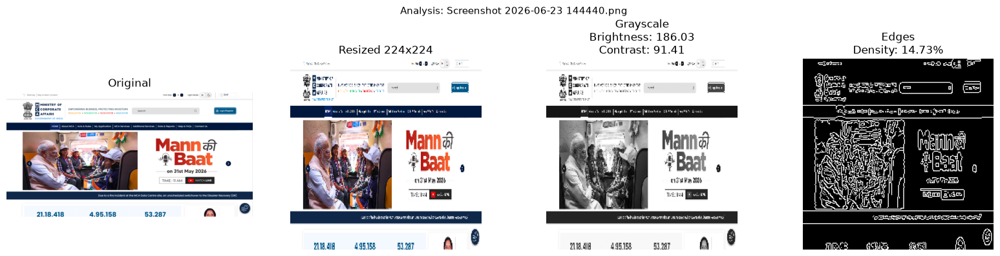

Image: Screenshot 2026-06-23 144440.png
  Brightness : 186.03/255
  Contrast   : 91.41
  Edge Density: 14.73%
----------------------------------------


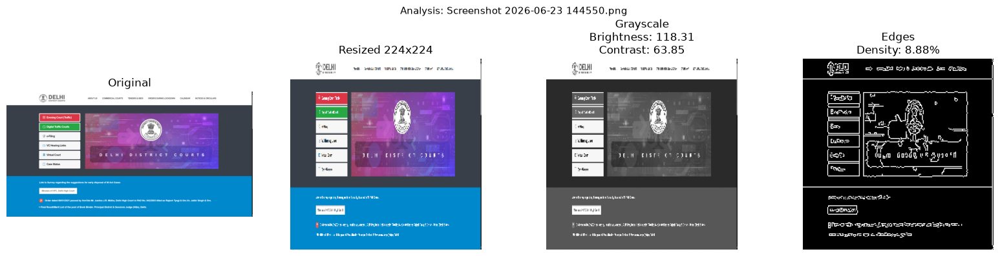

Image: Screenshot 2026-06-23 144550.png
  Brightness : 118.31/255
  Contrast   : 63.85
  Edge Density: 8.88%
----------------------------------------


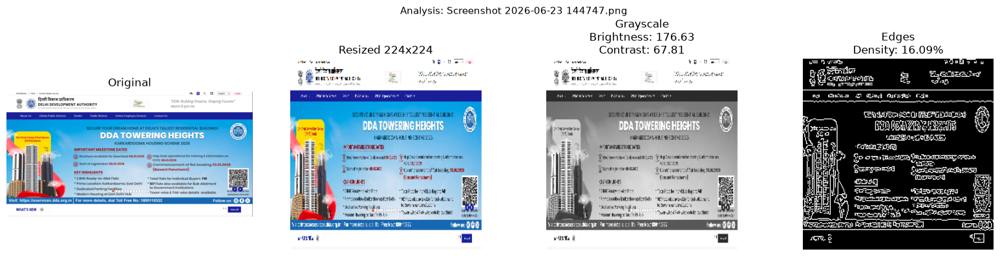

Image: Screenshot 2026-06-23 144747.png
  Brightness : 176.63/255
  Contrast   : 67.81
  Edge Density: 16.09%
----------------------------------------


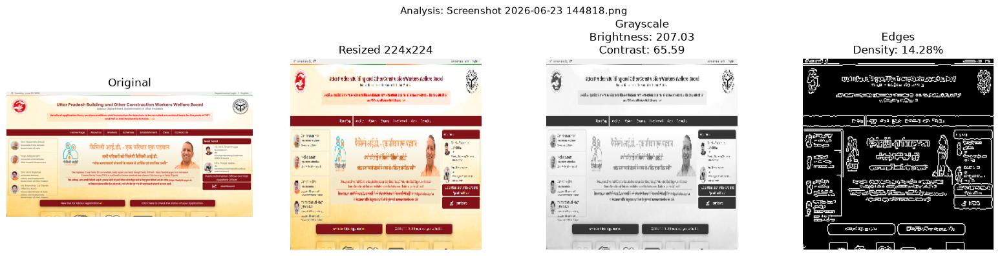

Image: Screenshot 2026-06-23 144818.png
  Brightness : 207.03/255
  Contrast   : 65.59
  Edge Density: 14.28%
----------------------------------------


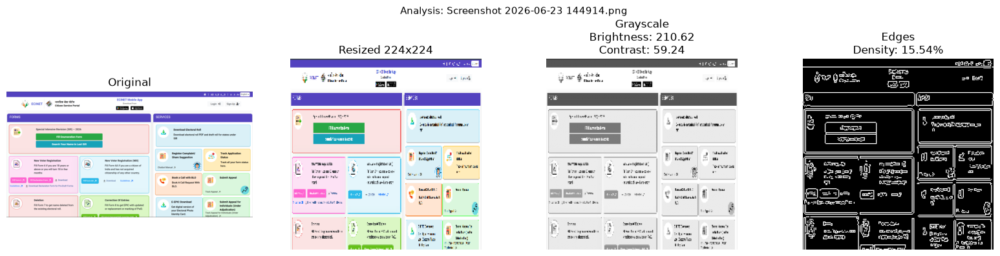

Image: Screenshot 2026-06-23 144914.png
  Brightness : 210.62/255
  Contrast   : 59.24
  Edge Density: 15.54%
----------------------------------------


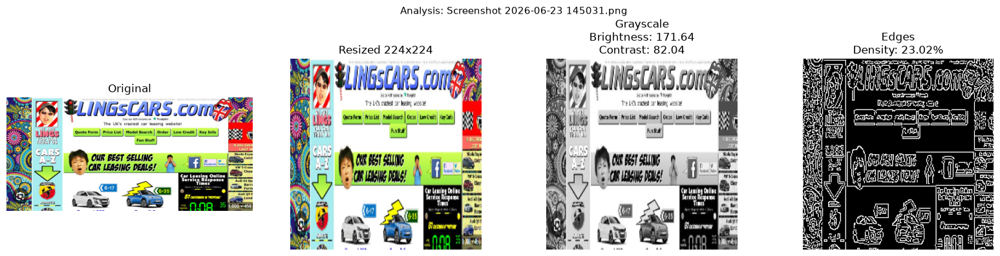

Image: Screenshot 2026-06-23 145031.png
  Brightness : 171.64/255
  Contrast   : 82.04
  Edge Density: 23.02%
----------------------------------------


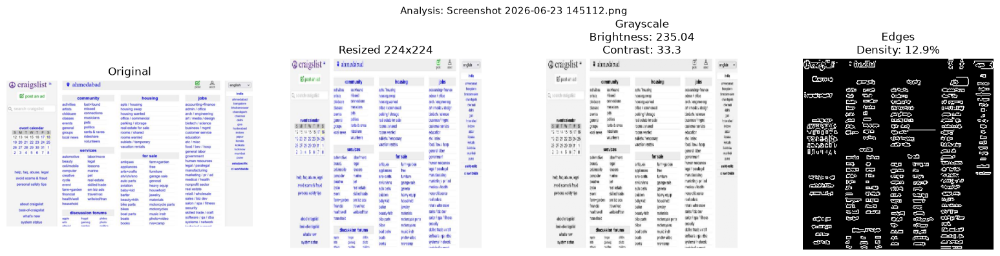

Image: Screenshot 2026-06-23 145112.png
  Brightness : 235.04/255
  Contrast   : 33.3
  Edge Density: 12.9%
----------------------------------------


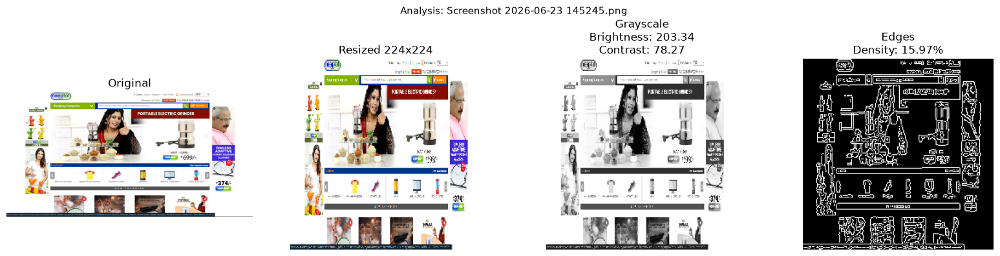

Image: Screenshot 2026-06-23 145245.png
  Brightness : 203.34/255
  Contrast   : 78.27
  Edge Density: 15.97%
----------------------------------------


In [10]:
# Final Loop - Process all 10 images
# Processing start hone ka heading print karta hai
print("="*60)
print(f"PROCESSING ALL {len(images)} IMAGES")
print("="*60)

# Sabhi images ko ek-ek karke process karta hai
for img_name in images:
    # Image ka complete path banata hai
    img_path = os.path.join(IMAGE_DIR, img_name)
    # Image read karta hai
    img = cv2.imread(img_path)
    # Image ko BGR se RGB format me convert karta hai
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # Image ko 224x224 size me resize karta hai
    img_resized = cv2.resize(img_rgb, (224, 224))
    # Image ko grayscale me convert karta hai
    img_gray = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)
    # np.mean() ka use image ki average brightness calculate karne ke liye kiya jata hai
    brightness = round(np.mean(img_gray), 2)
    # np.std() ka use image ka overall contrast calculate karne ke liye kiya jata hai
    contrast = round(np.std(img_gray), 2)
    # Canny Edge Detection apply karta hai
    edges = cv2.Canny(img_gray, 50, 150)
    # Edge pixels ka percentage (edge density) calculate karta hai
    edge_density = round(np.sum(edges > 0) / edges.size * 100, 2)

    # Figure ka size set karta hai
    plt.figure(figsize=(16, 4))

    # Pehla subplot create karta hai
    plt.subplot(1, 4, 1)
    # Original image display karta hai
    plt.imshow(img_rgb)
    # Title set karta hai
    plt.title("Original")
    # Axis hide karta hai
    plt.axis('off')

    # Dusra subplot create karta hai
    plt.subplot(1, 4, 2)
    # Resized image display karta hai
    plt.imshow(img_resized)
    # Title set karta hai
    plt.title("Resized 224x224")
    # Axis hide karta hai
    plt.axis('off')

    # Teesra subplot create karta hai
    plt.subplot(1, 4, 3)
    # Grayscale image display karta hai
    plt.imshow(img_gray, cmap='gray')
    # Brightness aur contrast title me show karta hai
    plt.title(f"Grayscale\nBrightness: {brightness}\nContrast: {contrast}")
    # Axis hide karta hai
    plt.axis('off')

    # Chautha subplot create karta hai
    plt.subplot(1, 4, 4)
    # Edge-detected image display karta hai
    plt.imshow(edges, cmap='gray')
    # Edge density title me show karta hai
    plt.title(f"Edges\nDensity: {edge_density}%")
    # Axis hide karta hai
    plt.axis('off')

    # Figure ka main title set karta hai
    plt.suptitle(f"Analysis: {img_name}", fontsize=11)
    # Layout automatically adjust karta hai
    plt.tight_layout()
    # Figure display karta hai
    plt.show()

    # Current image ka naam print karta hai
    print(f"Image: {img_name}")
    # Image ki brightness print karta hai
    print(f"  Brightness : {brightness}/255")
    # Image ka contrast print karta hai
    print(f"  Contrast   : {contrast}")
    # Image ki edge density print karta hai
    print(f"  Edge Density: {edge_density}%")
    # Next image ke output se separate karne ke liye line print karta hai
    print("-"*40)

In [11]:
# Summary table ki heading print karta hai
print("="*65)
print(f"{'#':<4} {'Image Name':<35} {'Brightness':>10} {'Contrast':>10} {'Edges%':>8}")
print("="*65)

# Sabhi images ko ek-ek karke process karta hai
for i, img_name in enumerate(images):
    # Image ka complete path banata hai
    img_path = os.path.join(IMAGE_DIR, img_name)
    # Image read karta hai
    img = cv2.imread(img_path)
    # Image ko BGR se RGB format me convert karta hai
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # Image ko 224x224 size me resize karta hai
    img_resized = cv2.resize(img_rgb, (224, 224))
    # Image ko grayscale me convert karta hai
    img_gray = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)
    # np.mean() ka use image ki average brightness calculate karne ke liye kiya jata hai
    brightness = round(np.mean(img_gray), 2)
    # np.std() ka use image ka overall contrast calculate karne ke liye kiya jata hai
    contrast = round(np.std(img_gray), 2)
    # Canny Edge Detection apply karta hai
    edges = cv2.Canny(img_gray, 50, 150)
    # Edge pixels ka percentage (edge density) calculate karta hai
    edge_density = round(np.sum(edges > 0) / edges.size * 100, 2)
    # Current image ke analysis results table format me print karta hai
    print(f"{i+1:<4} {img_name:<35} {brightness:>10} {contrast:>10} {edge_density:>8}")

# Summary table ka ending border print karta hai
print("="*65)
# Sabhi images successfully process hone ka message print karta hai
print(f"All {len(images)} images processed successfully!")

#    Image Name                          Brightness   Contrast   Edges%
1    Screenshot 2026-06-23 132015.png        159.84      82.34     20.8
2    Screenshot 2026-06-23 132334.png        192.77      85.01    12.82
3    Screenshot 2026-06-23 132939.png        210.06      63.68     8.21
4    Screenshot 2026-06-23 133431.png        221.01      66.69    10.75
5    Screenshot 2026-06-23 140930.png        226.09      46.63     6.97
6    Screenshot 2026-06-23 140957.png        239.11      53.22     7.26
7    Screenshot 2026-06-23 141031.png         23.66      37.79     6.01
8    Screenshot 2026-06-23 141056.png        216.54      67.66     4.88
9    Screenshot 2026-06-23 141120.png        201.37      82.85    11.76
10   Screenshot 2026-06-23 141744.png        197.41       76.5    10.62
11   Screenshot 2026-06-23 141920.png        216.64      69.56    11.09
12   Screenshot 2026-06-23 141947.png        197.05      62.23    16.99
13   Screenshot 2026-06-23 142025.png        205.69      57.77  